/Users/Vanshika/Documents/NSUT/DSA/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps | models: ['efficientnet_b2', 'resnet50']
ISIC2019: 24703 images -> 14885 after removing 9818 HAM10000 duplicates
  lesion grouping from ISIC_2019_Training_Metadata.csv: 4255 lesion ids
HAM10000 usable images: 10015 | ISIC2019 (deduped): 14885

train 17784 | val 3558 | test 3558  (no shared lesions / images)

Samples per split / source / class:
label           akiec   bcc   bkl  df   mel    nv  vasc
      source                                           
train HAM10000    234   366   785  82   795  4789   102
      ISIC2019    526  2005  1089  89  2435  4408    79
val   HAM10000     47    74   157  16   159   958    20
      ISIC2019    106   402   218  17   487   881    16
test  HAM10000     46    74   157  17   159   958    20
      ISIC2019    105   402   218  18   487   881    16


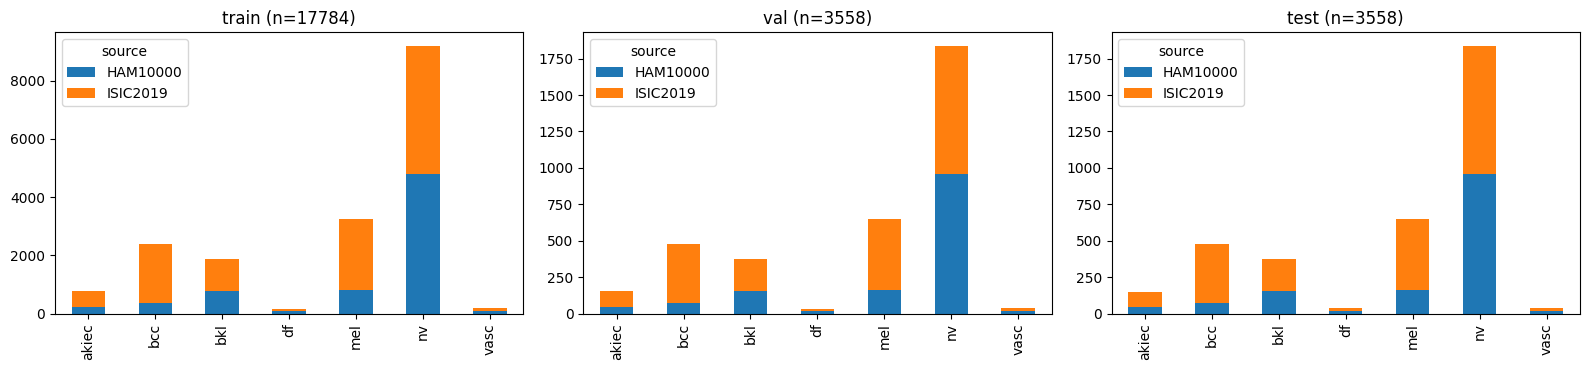


TRAINING efficientnet_b2


[efficientnet_b2] ep 01/50 loss 1.5067 | val acc 0.6762 bal_acc 0.5261 | 364s *saved*
[efficientnet_b2] ep 02/50 loss 1.0494 | val acc 0.6776 bal_acc 0.5729 | 359s *saved*
[efficientnet_b2] ep 03/50 loss 0.9214 | val acc 0.7099 bal_acc 0.5814 | 352s *saved*
[efficientnet_b2] ep 04/50 loss 0.8413 | val acc 0.7285 bal_acc 0.5932 | 357s *saved*
[efficientnet_b2] ep 05/50 loss 0.7725 | val acc 0.7389 bal_acc 0.6024 | 355s *saved*
[efficientnet_b2] ep 06/50 loss 0.7239 | val acc 0.7322 bal_acc 0.5998 | 359s
[efficientnet_b2] ep 07/50 loss 0.6767 | val acc 0.7327 bal_acc 0.5972 | 367s
[efficientnet_b2] ep 08/50 loss 0.6479 | val acc 0.7409 bal_acc 0.6220 | 369s *saved*
[efficientnet_b2] ep 09/50 loss 0.6216 | val acc 0.7473 bal_acc 0.6222 | 367s *saved*
[efficientnet_b2] ep 10/50 loss 0.5940 | val acc 0.7327 bal_acc 0.5991 | 367s
[efficientnet_b2] ep 11/50 loss 0.5792 | val acc 0.7395 bal_acc 0.5968 | 368s
[efficientnet_b2] ep 12/50 loss 0.5630 | val acc 0.7431 bal_acc 0.5931 | 367s
[efficie

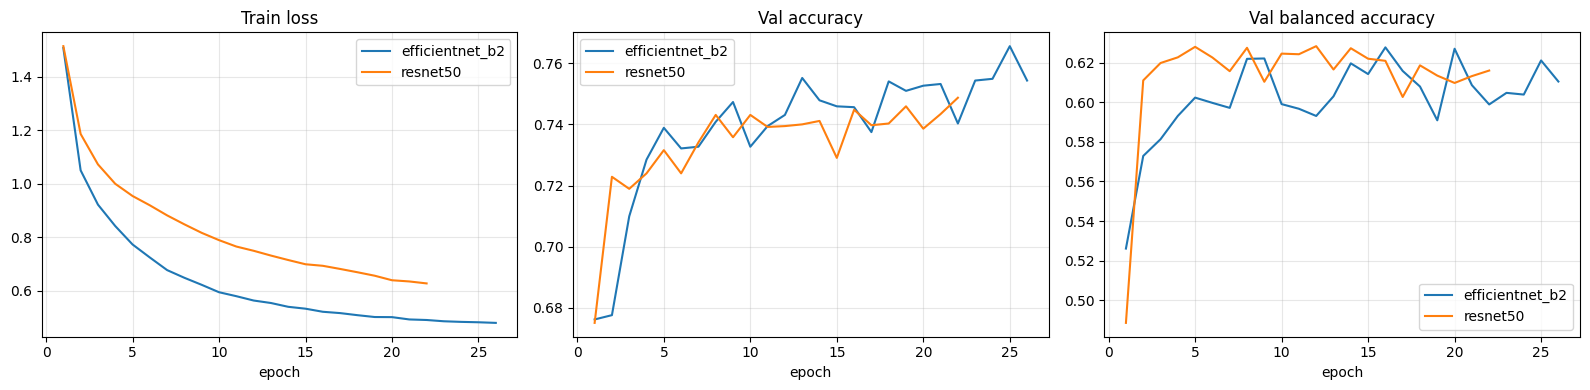


Validation HAM10000+ISIC2019 (used for model selection)  (n=3558)
          model  accuracy  top2_acc  balanced_acc  macro_precision  macro_recall  macro_f1  weighted_f1    mcc  kappa  macro_auc  macro_AP    ece  log_loss
efficientnet_b2    0.7456    0.8865        0.6278           0.6295        0.6278    0.6260       0.7424 0.6182 0.6180     0.9028    0.6517 0.0190    0.8094
       resnet50    0.7395    0.8890        0.6284           0.6048        0.6284    0.6129       0.7388 0.6127 0.6123     0.8914    0.6411 0.0159    0.7992
ENSEMBLE (mean)    0.7645    0.9061        0.6387           0.6484        0.6387    0.6389       0.7607 0.6453 0.6449     0.9204    0.6922 0.0455    0.7171

Ensemble 95% bootstrap CI:  accuracy [0.7513, 0.7778] | balanced_acc [0.6012, 0.6733] | macro_f1 [0.6008, 0.6686]
double-fault efficientnet_b2 & resnet50: 0.1709 | disagreement: 0.2212

Ensemble classification report:
              precision    recall  f1-score   support

       akiec      0.536     0.438  

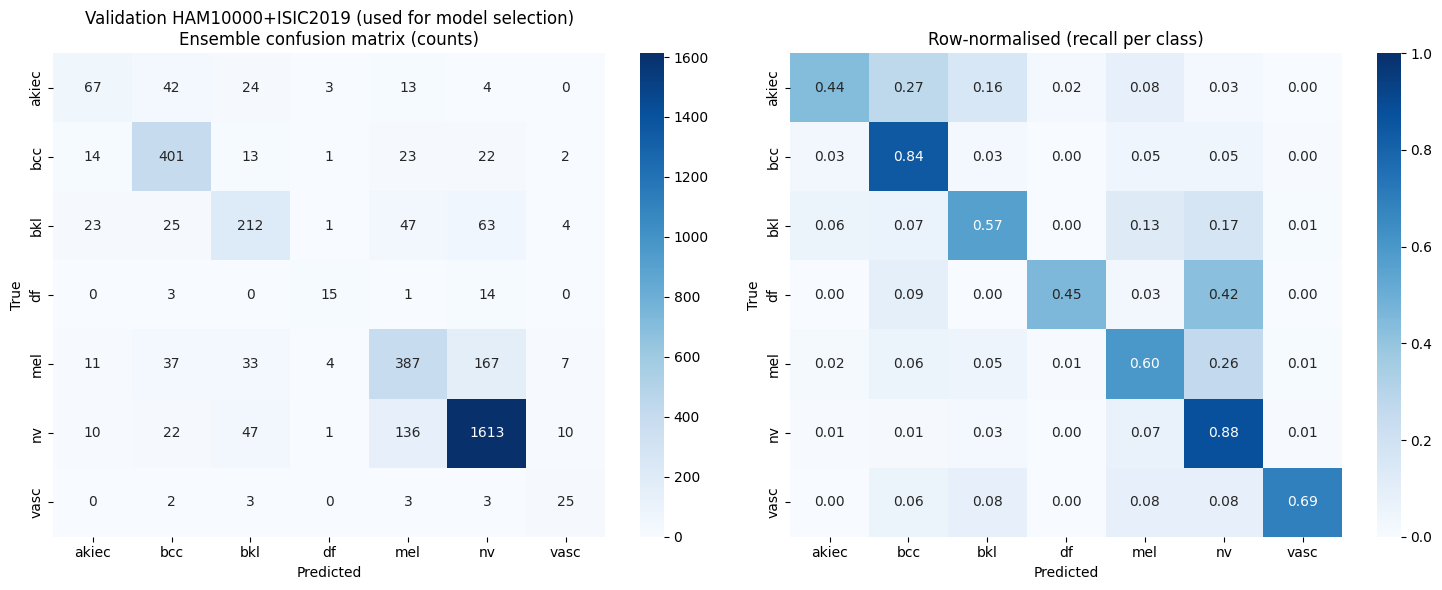

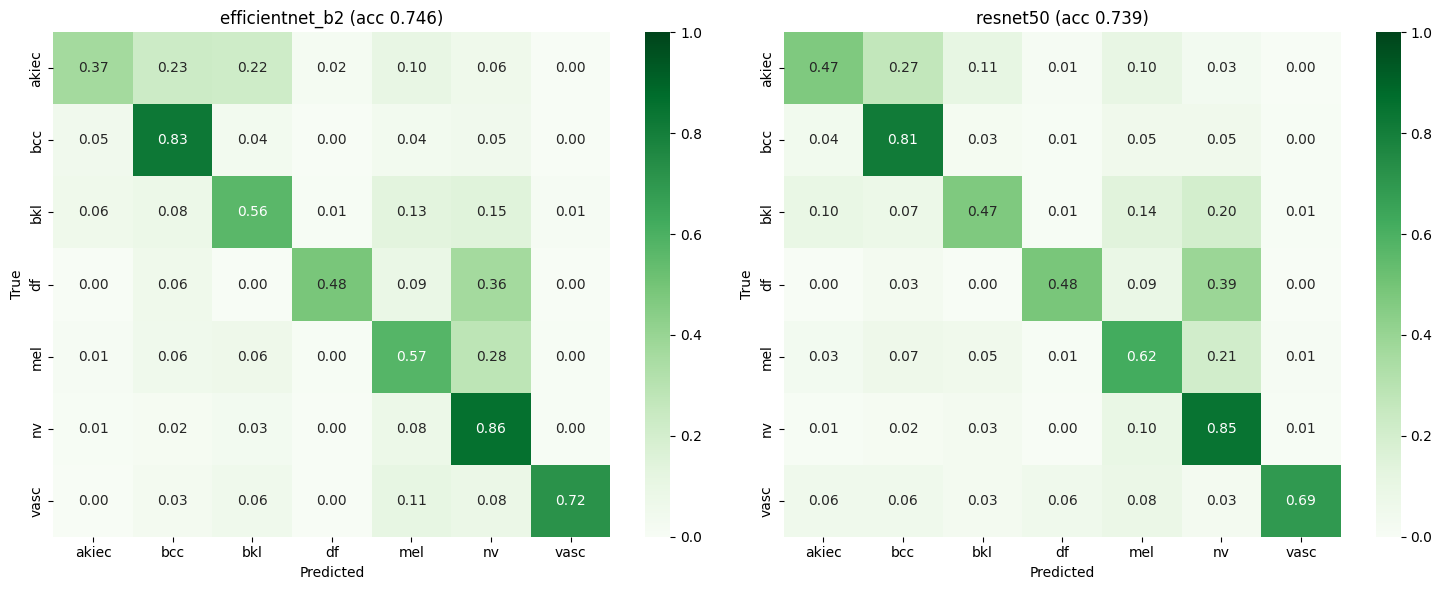

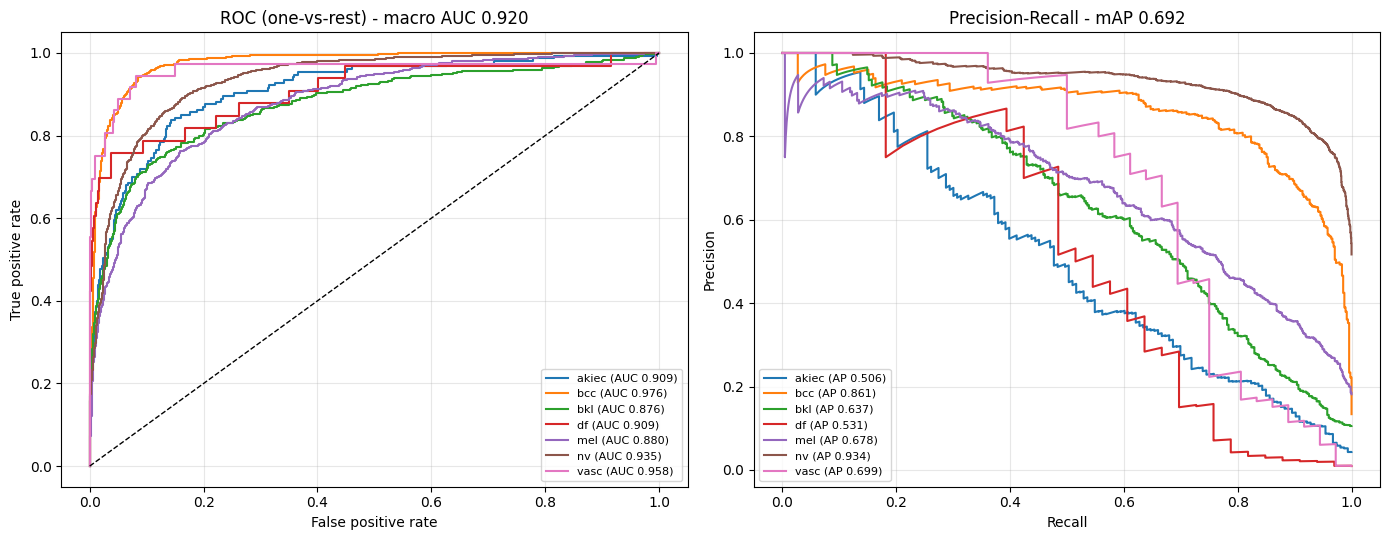

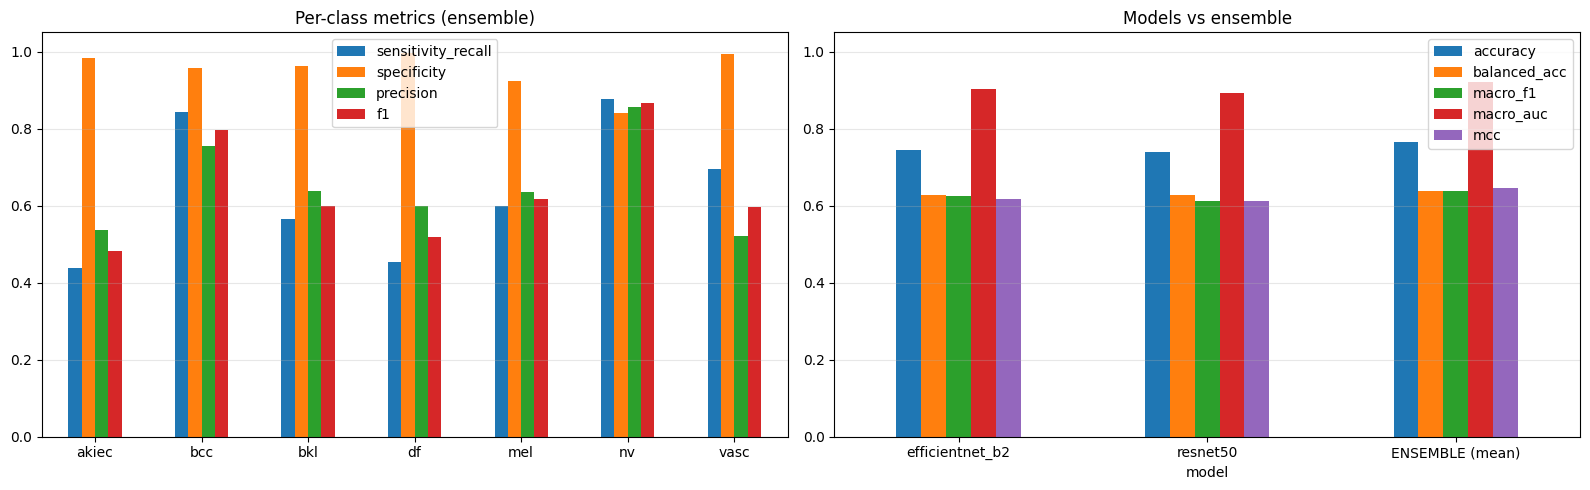

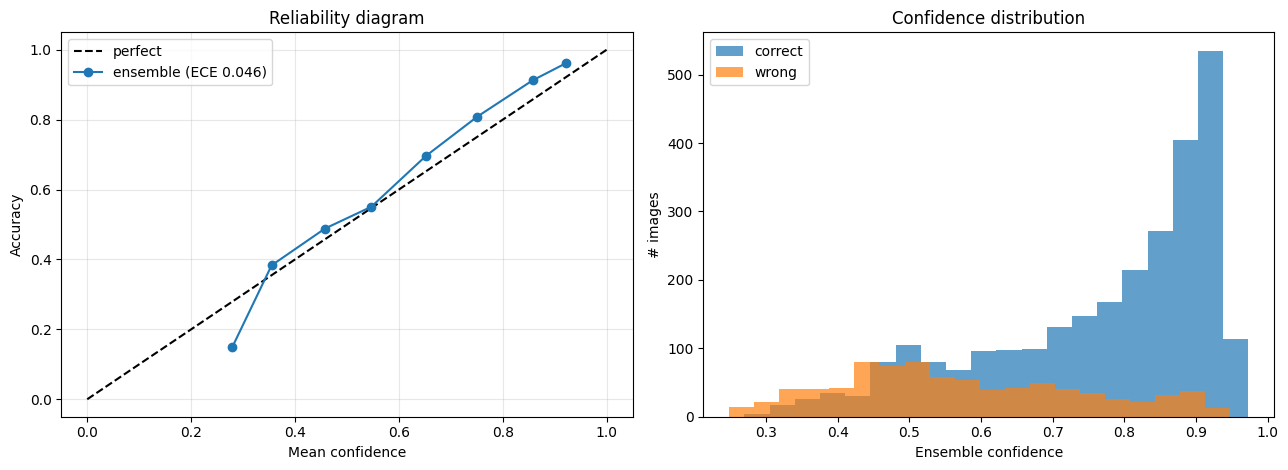

  val HAM10000: n=1431  ensemble acc = 0.8560
  val ISIC2019: n=2127  ensemble acc = 0.7029


In [1]:
# ===================== CELL 1: TRAIN ON HAM10000 + ISIC2019 (COMBINED) =====================
# pip install torch torchvision timm pandas numpy scikit-learn matplotlib seaborn pillow
# Run this notebook from inside "CV Lab Project/" (the folder that contains data/).
#
# Same models / preprocessing / training recipe as before (EfficientNet-B2 + ResNet50, mean-probability ensemble),
# but trained on the COMBINATION of the two datasets.
#
# Leakage controls:
#  * ISIC2019 contains the HAM10000 images -> they are removed from ISIC2019 by image id, so no image is duplicated.
#  * Each dataset is split train / val / test BY lesion (HAM: lesion_id; ISIC2019: lesion_id from the metadata CSV
#    if present, otherwise every image is its own group), stratified by class. No lesion is in two partitions.
#  * Only the train split is augmented / oversampled. Best epoch is chosen on val only.
#  * The HAM10000 test split (cell 2) and the ISIC2019 test split (cell 3) are touched only for final evaluation.

import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import timm
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, matthews_corrcoef, cohen_kappa_score,
                             roc_curve, auc, precision_recall_curve, average_precision_score, log_loss)
warnings.filterwarnings("ignore")

# ------------------------- config -------------------------
TAG = "nb2_effnet_resnet50_combined"
MODEL_NAMES = ['efficientnet_b2', 'resnet50']          # timm model names
LR = {"swin_tiny_patch4_window7_224": 5e-5, "convnext_tiny": 5e-5}   # default 1e-4
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
NUM_CLASSES = len(CLASSES)
IMG = 224
BATCH = 32
EPOCHS = 50
PATIENCE = 10                      # early stop if val balanced acc does not improve for 10 epochs
SEED = 42

BASE = Path.cwd()
DATA = BASE / "data"
HAM_CSV = DATA / "HAM10000_metadata.csv"
HAM_IMGS = DATA / "images"
ISIC_DIR = DATA / "ISIC2019_Dataset"
MODEL_DIR = BASE / "models"; MODEL_DIR.mkdir(exist_ok=True)
OUT_DIR = BASE / "research_results"; OUT_DIR.mkdir(exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
NUM_WORKERS = 4 if DEVICE.type == "cuda" else 0
print("Device:", DEVICE, "| models:", MODEL_NAMES)

# ------------------------- data frames -------------------------
def build_ham_df():
    ham = pd.read_csv(HAM_CSV)
    paths = {p.stem: str(p) for p in HAM_IMGS.rglob("*.jpg")}
    ham = ham[ham["image_id"].isin(paths)].copy()
    ham["path"] = ham["image_id"].map(paths)
    ham["label"] = ham["dx"]
    ham["group"] = "HAM_" + ham["lesion_id"].astype(str)
    ham["y"] = ham["label"].map({c: i for i, c in enumerate(CLASSES)})
    ham["source"] = "HAM10000"
    return ham[["image_id", "path", "label", "group", "y", "source"]].reset_index(drop=True)

ISIC_FOLDER_TO_DX = {"AK": "akiec", "BCC": "bcc", "BKL": "bkl", "DF": "df",
                     "MEL": "mel", "NV": "nv", "VASC": "vasc"}   # SCC is not in the 7-class space

def build_isic_df(ham_ids):
    rows = []
    for folder, dx in ISIC_FOLDER_TO_DX.items():
        for p in (ISIC_DIR / folder).rglob("*.jpg"):
            rows.append((p.stem, str(p), dx))
    df = pd.DataFrame(rows, columns=["image_id", "path", "label"])
    n0 = len(df)
    df = df[~df["image_id"].isin(ham_ids)].reset_index(drop=True)      # drop HAM10000 duplicates
    print(f"ISIC2019: {n0} images -> {len(df)} after removing {n0 - len(df)} HAM10000 duplicates")
    # lesion grouping (optional): use the official metadata CSV if it can be found
    df["group"] = "ISIC_" + df["image_id"]
    metas = list(ISIC_DIR.rglob("*Metadata*.csv")) + list(DATA.glob("*ISIC*Metadata*.csv"))
    for mp in metas:
        m = pd.read_csv(mp)
        if {"image", "lesion_id"} <= set(m.columns):
            mp_ = m.dropna(subset=["lesion_id"]).set_index("image")["lesion_id"].astype(str).to_dict()
            df["group"] = [("ISIC_L_" + mp_[i]) if i in mp_ else g for i, g in zip(df["image_id"], df["group"])]
            print(f"  lesion grouping from {mp.name}: {len(set(mp_[i] for i in df['image_id'] if i in mp_))} lesion ids")
            break
    else:
        print("  (no ISIC metadata with lesion_id found -> each ISIC image is its own group)")
    df["y"] = df["label"].map({c: i for i, c in enumerate(CLASSES)})
    df["source"] = "ISIC2019"
    return df[["image_id", "path", "label", "group", "y", "source"]]

ham_all = build_ham_df()
isic_all = build_isic_df(set(ham_all["image_id"]))
print("HAM10000 usable images:", len(ham_all), "| ISIC2019 (deduped):", len(isic_all))

def split3(df):
    """lesion-grouped, stratified 3-way split (~72% train / ~12% val / ~14% test)"""
    sg1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
    trval_idx, test_idx = next(sg1.split(df, df["y"], df["group"]))
    trval, te = df.iloc[trval_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
    sg2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
    tr_idx, va_idx = next(sg2.split(trval, trval["y"], trval["group"]))
    return trval.iloc[tr_idx].reset_index(drop=True), trval.iloc[va_idx].reset_index(drop=True), te

ham_tr, ham_va, ham_te = split3(ham_all)
isic_tr, isic_va, isic_te = split3(isic_all)

train_df = pd.concat([ham_tr, isic_tr], ignore_index=True)
val_df = pd.concat([ham_va, isic_va], ignore_index=True)
test_df = pd.concat([ham_te, isic_te], ignore_index=True)          # = HAM test + ISIC test (cells 2 and 3)

# leakage checks
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert not (set(a["group"]) & set(b["group"])), "lesion leakage!"
    assert not (set(a["image_id"]) & set(b["image_id"])), "image leakage!"
print(f"\ntrain {len(train_df)} | val {len(val_df)} | test {len(test_df)}  (no shared lesions / images)")
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d.to_csv(OUT_DIR / f"{TAG}_{n}_split.csv", index=False)

# class / source distribution per split
dist = pd.concat({n: d.groupby(["source", "label"]).size().unstack(fill_value=0).reindex(columns=CLASSES, fill_value=0)
                  for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]})
print("\nSamples per split / source / class:"); print(dist.to_string())
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8), sharey=False)
for ax, (n, d) in zip(axs, [("train", train_df), ("val", val_df), ("test", test_df)]):
    d.groupby(["label", "source"]).size().unstack(fill_value=0).reindex(CLASSES).plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(f"{n} (n={len(d)})"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(OUT_DIR / f"{TAG}_class_distribution.png", dpi=150); plt.show()

# ------------------------- preprocessing / datasets -------------------------
def shades_of_gray(img, p=6):          # colour constancy -> helps cross-dataset transfer
    x = np.asarray(img, dtype=np.float32)
    illum = np.power(np.mean(np.power(x, p), axis=(0, 1)), 1.0 / p) + 1e-6
    illum = illum / np.linalg.norm(illum)
    x = x / (illum * np.sqrt(3.0))
    return Image.fromarray(np.clip(x, 0, 255).astype(np.uint8))

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomAffine(degrees=30, translate=(0.1, 0.1), scale=(0.85, 1.15), shear=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.ToTensor()])
eval_tf = transforms.ToTensor()

class LesionDS(Dataset):
    def __init__(self, df, train):
        self.paths, self.y, self.tf = df["path"].tolist(), df["y"].values, (train_tf if train else eval_tf)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB").resize((IMG, IMG), Image.BILINEAR)
        return self.tf(shades_of_gray(img)), int(self.y[i])

counts = train_df["y"].value_counts().reindex(range(NUM_CLASSES)).values.astype(float)
sample_w = (1.0 / np.sqrt(counts))[train_df["y"].values]      # mild minority oversampling, train only
sampler = WeightedRandomSampler(sample_w, num_samples=len(train_df), replacement=True)
train_loader = DataLoader(LesionDS(train_df, True), BATCH, sampler=sampler, num_workers=NUM_WORKERS)
val_loader = DataLoader(LesionDS(val_df, False), BATCH, num_workers=NUM_WORKERS)

# ------------------------- models -------------------------
class Wrapped(nn.Module):
    # takes [0,1] images, applies each backbone's own ImageNet normalisation
    def __init__(self, name):
        super().__init__()
        self.m = timm.create_model(name, pretrained=True, num_classes=NUM_CLASSES)
        cfg = timm.data.resolve_data_config({}, model=self.m)
        self.register_buffer("mean", torch.tensor(cfg["mean"]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(cfg["std"]).view(1, 3, 1, 1))
    def forward(self, x): return self.m((x - self.mean) / self.std)

@torch.no_grad()
def predict_loader(model, loader):
    model.eval(); out = []
    for x, _ in loader:
        out.append(F.softmax(model(x.to(DEVICE)).float(), 1).cpu().numpy())
    return np.concatenate(out)

HISTORY = {}
def train_model(name):
    model = Wrapped(name).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR.get(name, 1e-4), weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    best, bad, ckpt = -1, 0, MODEL_DIR / f"{TAG}_{name}.pth"
    hist = dict(loss=[], val_acc=[], val_bal=[])
    for ep in range(1, EPOCHS + 1):
        model.train(); t0, run = time.time(), 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast(device_type="cuda", enabled=use_amp):
                loss = F.cross_entropy(model(x), y, label_smoothing=0.1)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item() * x.size(0)
        sched.step()
        pv = predict_loader(model, val_loader)
        bal = balanced_accuracy_score(val_df["y"].values, pv.argmax(1))    # selection metric (val only)
        acc = accuracy_score(val_df["y"].values, pv.argmax(1))
        hist["loss"].append(run / len(train_df)); hist["val_acc"].append(acc); hist["val_bal"].append(bal)
        flag = ""
        if bal > best:
            best, bad, flag = bal, 0, " *saved*"; torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        print(f"[{name}] ep {ep:02d}/{EPOCHS} loss {run/len(train_df):.4f} | val acc {acc:.4f} bal_acc {bal:.4f} | {time.time()-t0:.0f}s{flag}")
        if bad >= PATIENCE:
            print("early stop"); break
    HISTORY[name] = hist
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); model.eval()
    return model

MODELS = {}
for n in MODEL_NAMES:
    print("\n" + "=" * 70 + f"\nTRAINING {n}\n" + "=" * 70)
    MODELS[n] = train_model(n)

# training curves
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for n, h in HISTORY.items():
    ep = range(1, len(h["loss"]) + 1)
    axs[0].plot(ep, h["loss"], label=n); axs[1].plot(ep, h["val_acc"], label=n); axs[2].plot(ep, h["val_bal"], label=n)
for ax, t in zip(axs, ["Train loss", "Val accuracy", "Val balanced accuracy"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / f"{TAG}_training_curves.png", dpi=150); plt.show()

# ------------------------- shared inference / reporting helpers -------------------------
def get_probs(df):
    loader = DataLoader(LesionDS(df, False), BATCH, num_workers=NUM_WORKERS)
    return {n: predict_loader(m, loader) for n, m in MODELS.items()}

def _ece(p, y, bins=15):
    conf, pred = p.max(1), p.argmax(1)
    edges, e = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return e

def _macro_auc_ap(y, p, present):
    Y = label_binarize(y, classes=range(NUM_CLASSES))
    aucs, aps = [], []
    for c in present:
        if 0 < Y[:, c].sum() < len(y):
            aucs.append(auc(*roc_curve(Y[:, c], p[:, c])[:2])); aps.append(average_precision_score(Y[:, c], p[:, c]))
    return (np.mean(aucs) if aucs else np.nan), (np.mean(aps) if aps else np.nan)

def full_report(title, y, P):
    """Accuracy + every other metric, per-class table, bootstrap CIs and all plots. P = {model_name: probs}."""
    y = np.asarray(y); n = len(y)
    safe = "".join(ch if ch.isalnum() else "_" for ch in title)
    ens = np.mean([P[k] for k in MODEL_NAMES], axis=0)
    allp = dict(P); allp["ENSEMBLE (mean)"] = ens
    present = [c for c in range(NUM_CLASSES) if (y == c).any()]
    pred = ens.argmax(1)

    # ---- 1. overall metrics for every model + ensemble
    rows = []
    for k, p in allp.items():
        pr = p.argmax(1); mauc, mapr = _macro_auc_ap(y, p, present)
        rows.append(dict(model=k, accuracy=accuracy_score(y, pr),
                         top2_acc=np.mean([y[i] in np.argsort(-p[i])[:2] for i in range(n)]),
                         balanced_acc=balanced_accuracy_score(y, pr),
                         macro_precision=precision_score(y, pr, labels=present, average="macro", zero_division=0),
                         macro_recall=recall_score(y, pr, labels=present, average="macro", zero_division=0),
                         macro_f1=f1_score(y, pr, labels=present, average="macro", zero_division=0),
                         weighted_f1=f1_score(y, pr, labels=present, average="weighted", zero_division=0),
                         mcc=matthews_corrcoef(y, pr), kappa=cohen_kappa_score(y, pr),
                         macro_auc=mauc, macro_AP=mapr, ece=_ece(p, y),
                         log_loss=log_loss(y, np.clip(p, 1e-7, 1), labels=list(range(NUM_CLASSES)))))
    summ = pd.DataFrame(rows)
    print("\n" + "=" * 90 + f"\n{title}  (n={n})\n" + "=" * 90)
    print(summ.round(4).to_string(index=False))
    summ.to_csv(OUT_DIR / f"{TAG}_{safe}_summary.csv", index=False)

    # ---- 2. bootstrap 95% CI (ensemble)
    rng, bs = np.random.default_rng(SEED), []
    for _ in range(500):
        i = rng.integers(0, n, n)
        bs.append((accuracy_score(y[i], pred[i]), balanced_accuracy_score(y[i], pred[i]),
                   f1_score(y[i], pred[i], labels=present, average="macro", zero_division=0)))
    bs = np.array(bs); lo, hi = np.percentile(bs, 2.5, axis=0), np.percentile(bs, 97.5, axis=0)
    print("\nEnsemble 95% bootstrap CI:  " + " | ".join(
        f"{m} [{a:.4f}, {b:.4f}]" for m, a, b in zip(["accuracy", "balanced_acc", "macro_f1"], lo, hi)))

    # ---- 3. complementarity between the base models
    ks = list(P)
    for i in range(len(ks)):
        for j in range(i + 1, len(ks)):
            wi, wj = P[ks[i]].argmax(1) != y, P[ks[j]].argmax(1) != y
            print(f"double-fault {ks[i]} & {ks[j]}: {(wi & wj).mean():.4f} | disagreement: "
                  f"{(P[ks[i]].argmax(1) != P[ks[j]].argmax(1)).mean():.4f}")

    # ---- 4. classification report + per-class table
    print("\nEnsemble classification report:")
    print(classification_report(y, pred, labels=present, target_names=[CLASSES[c] for c in present], digits=3, zero_division=0))
    cm = confusion_matrix(y, pred, labels=range(NUM_CLASSES))
    tp = np.diag(cm).astype(float); fn = cm.sum(1) - tp; fp = cm.sum(0) - tp; tn = n - tp - fn - fp
    dv = lambda a, b: np.divide(a, b, out=np.zeros_like(a, dtype=float), where=b > 0)
    sens, spec, prec = dv(tp, tp + fn), dv(tn, tn + fp), dv(tp, tp + fp)
    f1c = dv(2 * prec * sens, prec + sens)
    Y = label_binarize(y, classes=range(NUM_CLASSES)); aucs, aps = np.full(NUM_CLASSES, np.nan), np.full(NUM_CLASSES, np.nan)
    for c in range(NUM_CLASSES):
        if 0 < Y[:, c].sum() < n:
            aucs[c] = auc(*roc_curve(Y[:, c], ens[:, c])[:2]); aps[c] = average_precision_score(Y[:, c], ens[:, c])
    pc = pd.DataFrame(dict(sensitivity_recall=sens, specificity=spec, precision=prec, f1=f1c, auc=aucs, ap=aps,
                           support=cm.sum(1)), index=CLASSES)
    print("Per-class metrics (ensemble):"); print(pc.round(4).to_string())
    pc.to_csv(OUT_DIR / f"{TAG}_{safe}_per_class.csv")
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    off = [(CLASSES[i], CLASSES[j], cm[i, j], cmn[i, j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES)
           if i != j and cm[i, j] > 0]
    print("\nMost frequent confusions (true -> predicted):")
    for t, p_, c_, r_ in sorted(off, key=lambda z: -z[2])[:6]: print(f"  {t:>5} -> {p_:<5} {c_:>5} images ({r_*100:.1f}% of {t})")

    # ---- 5. FIGURE: confusion-matrix heatmaps (counts + row-normalised)
    fig, axs = plt.subplots(1, 2, figsize=(15, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axs[0])
    axs[0].set_title(f"{title}\nEnsemble confusion matrix (counts)")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=axs[1])
    axs[1].set_title("Row-normalised (recall per class)")
    for a in axs: a.set_xlabel("Predicted"); a.set_ylabel("True")
    plt.tight_layout(); plt.savefig(OUT_DIR / f"{TAG}_{safe}_cm.png", dpi=150); plt.show()

    # ---- 6. FIGURE: per-model normalised confusion matrices
    fig, axs = plt.subplots(1, len(P), figsize=(7.5 * len(P), 6))
    for ax, k in zip(np.atleast_1d(axs), P):
        c_ = confusion_matrix(y, P[k].argmax(1), labels=range(NUM_CLASSES))
        sns.heatmap(c_ / np.maximum(c_.sum(1, keepdims=True), 1), annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1,
                    xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
        ax.set_title(f"{k} (acc {accuracy_score(y, P[k].argmax(1)):.3f})"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    plt.tight_layout(); plt.savefig(OUT_DIR / f"{TAG}_{safe}_cm_per_model.png", dpi=150); plt.show()

    # ---- 7. FIGURE: ROC + precision-recall curves (ensemble)
    fig, axs = plt.subplots(1, 2, figsize=(14, 5.5)); cols = plt.cm.tab10(np.arange(NUM_CLASSES))
    for c in present:
        if not (0 < Y[:, c].sum() < n): continue
        fpr, tpr, _ = roc_curve(Y[:, c], ens[:, c]); axs[0].plot(fpr, tpr, color=cols[c], label=f"{CLASSES[c]} (AUC {aucs[c]:.3f})")
        pr_, rc_, _ = precision_recall_curve(Y[:, c], ens[:, c]); axs[1].plot(rc_, pr_, color=cols[c], label=f"{CLASSES[c]} (AP {aps[c]:.3f})")
    axs[0].plot([0, 1], [0, 1], "k--", lw=1); axs[0].set_title(f"ROC (one-vs-rest) - macro AUC {np.nanmean(aucs):.3f}")
    axs[0].set_xlabel("False positive rate"); axs[0].set_ylabel("True positive rate")
    axs[1].set_title(f"Precision-Recall - mAP {np.nanmean(aps):.3f}"); axs[1].set_xlabel("Recall"); axs[1].set_ylabel("Precision")
    for a in axs: a.legend(loc="best", fontsize=8); a.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"{TAG}_{safe}_roc_pr.png", dpi=150); plt.show()

    # ---- 8. FIGURE: per-class metrics + model comparison
    fig, axs = plt.subplots(1, 2, figsize=(16, 5))
    pc[["sensitivity_recall", "specificity", "precision", "f1"]].plot(kind="bar", ax=axs[0], rot=0)
    axs[0].set_ylim(0, 1.05); axs[0].set_title("Per-class metrics (ensemble)"); axs[0].grid(axis="y", alpha=.3)
    summ.set_index("model")[["accuracy", "balanced_acc", "macro_f1", "macro_auc", "mcc"]].plot(kind="bar", ax=axs[1], rot=0)
    axs[1].set_ylim(0, 1.05); axs[1].set_title("Models vs ensemble"); axs[1].grid(axis="y", alpha=.3)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"{TAG}_{safe}_metrics_bars.png", dpi=150); plt.show()

    # ---- 9. FIGURE: calibration (reliability diagram) + confidence histogram
    conf, ok = ens.max(1), pred == y
    edges = np.linspace(0, 1, 11); mids, accs, cnts = [], [], []
    for l_, h_ in zip(edges[:-1], edges[1:]):
        m = (conf > l_) & (conf <= h_)
        if m.any(): mids.append(conf[m].mean()); accs.append(ok[m].mean()); cnts.append(m.sum())
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
    axs[0].plot([0, 1], [0, 1], "k--", label="perfect"); axs[0].plot(mids, accs, "o-", label=f"ensemble (ECE {_ece(ens, y):.3f})")
    axs[0].set_xlabel("Mean confidence"); axs[0].set_ylabel("Accuracy"); axs[0].set_title("Reliability diagram"); axs[0].legend(); axs[0].grid(alpha=.3)
    axs[1].hist(conf[ok], bins=20, alpha=.7, label="correct"); axs[1].hist(conf[~ok], bins=20, alpha=.7, label="wrong")
    axs[1].set_xlabel("Ensemble confidence"); axs[1].set_ylabel("# images"); axs[1].set_title("Confidence distribution"); axs[1].legend()
    plt.tight_layout(); plt.savefig(OUT_DIR / f"{TAG}_{safe}_calibration.png", dpi=150); plt.show()
    return summ, pc

# ------------------------- validation (model-selection set, NOT a test result) -------------------------
PROBS = {}
PROBS["val"] = get_probs(val_df)
full_report("Validation HAM10000+ISIC2019 (used for model selection)", val_df["y"].values, PROBS["val"])
for src in ["HAM10000", "ISIC2019"]:
    m = (val_df["source"] == src).values
    print(f"  val {src}: n={m.sum()}  ensemble acc = "
          f"{accuracy_score(val_df['y'].values[m], np.mean([PROBS['val'][k][m] for k in MODEL_NAMES], 0).argmax(1)):.4f}")

HAM10000 test images: 1431
label
akiec     46
bcc       74
bkl      157
df        17
mel      159
nv       958
vasc      20

HAM10000 held-out test  (n=1431)
          model  accuracy  top2_acc  balanced_acc  macro_precision  macro_recall  macro_f1  weighted_f1    mcc  kappa  macro_auc  macro_AP    ece  log_loss
efficientnet_b2    0.7959    0.9119        0.6120           0.6708        0.6120    0.6346       0.7859 0.5942 0.5914     0.9115    0.6666 0.0402    0.6423
       resnet50    0.8148    0.9315        0.6496           0.6558        0.6496    0.6472       0.8125 0.6412 0.6404     0.9374    0.6826 0.0454    0.5842
ENSEMBLE (mean)    0.8288    0.9371        0.6572           0.7060        0.6572    0.6727       0.8219 0.6619 0.6589     0.9465    0.7141 0.0672    0.5470

Ensemble 95% bootstrap CI:  accuracy [0.8103, 0.8491] | balanced_acc [0.6056, 0.7120] | macro_f1 [0.6200, 0.7158]
double-fault efficientnet_b2 & resnet50: 0.1237 | disagreement: 0.1656

Ensemble classification report:

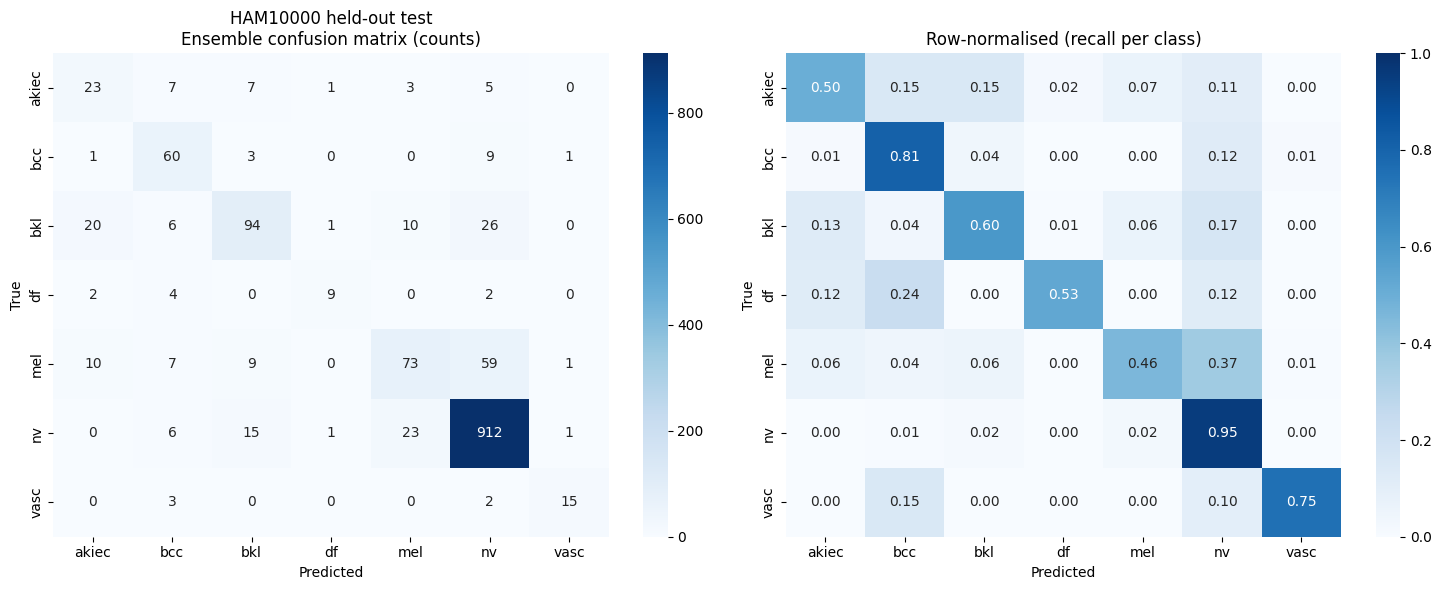

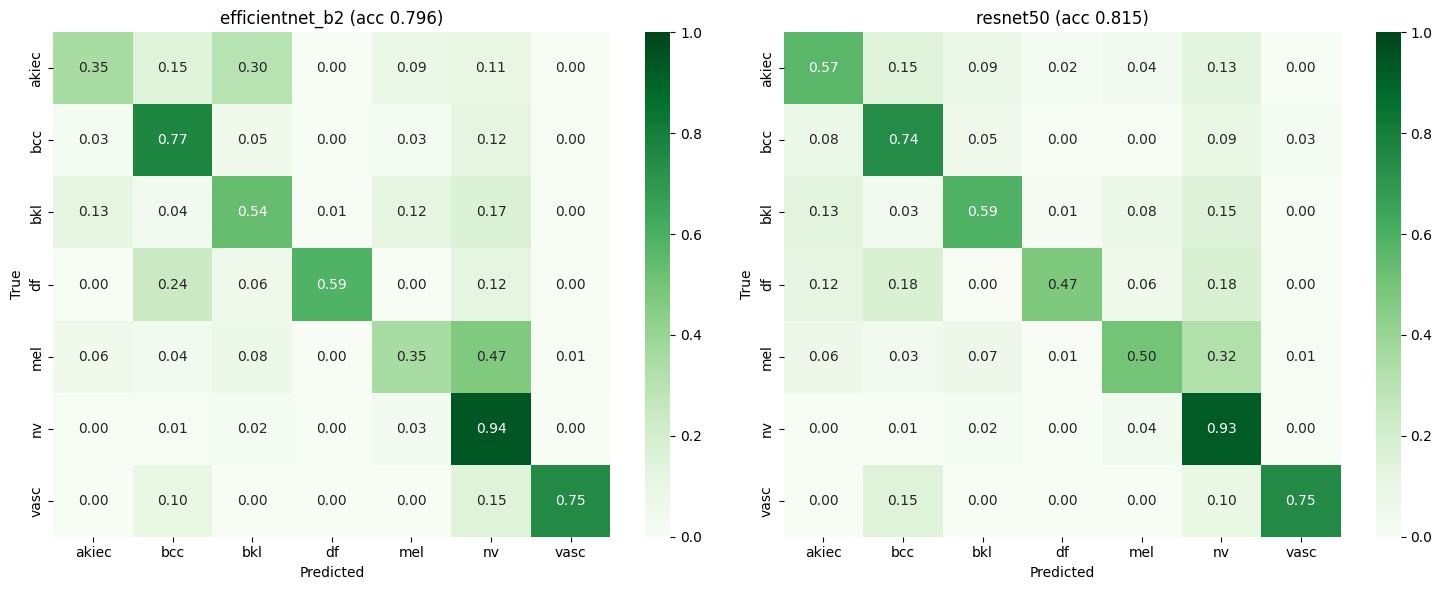

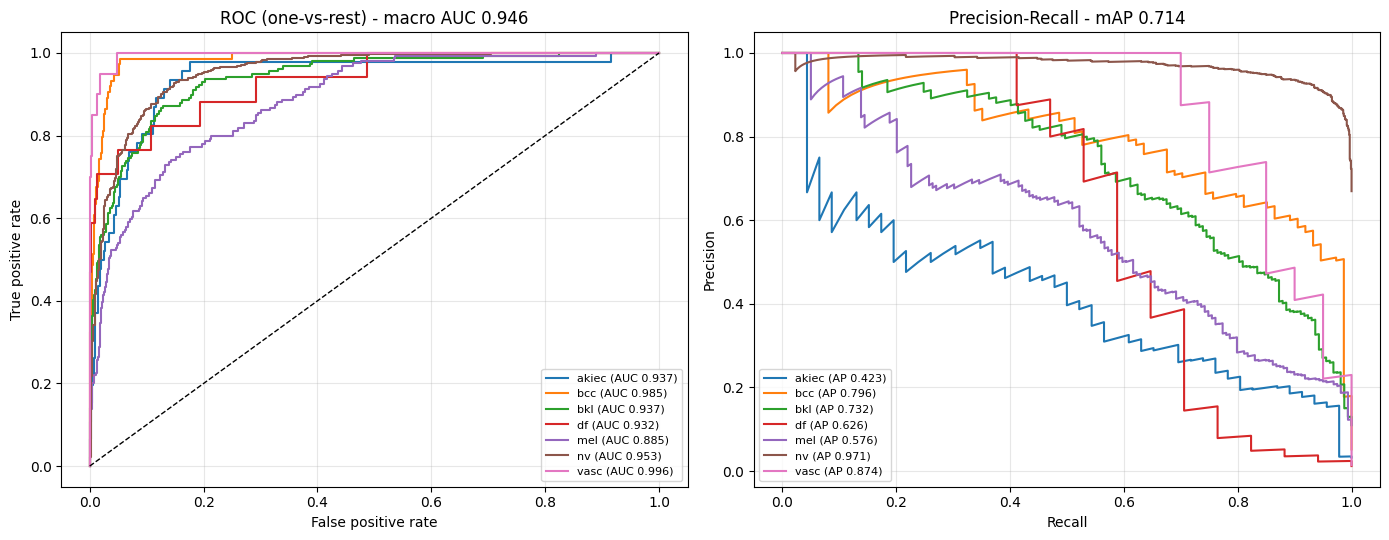

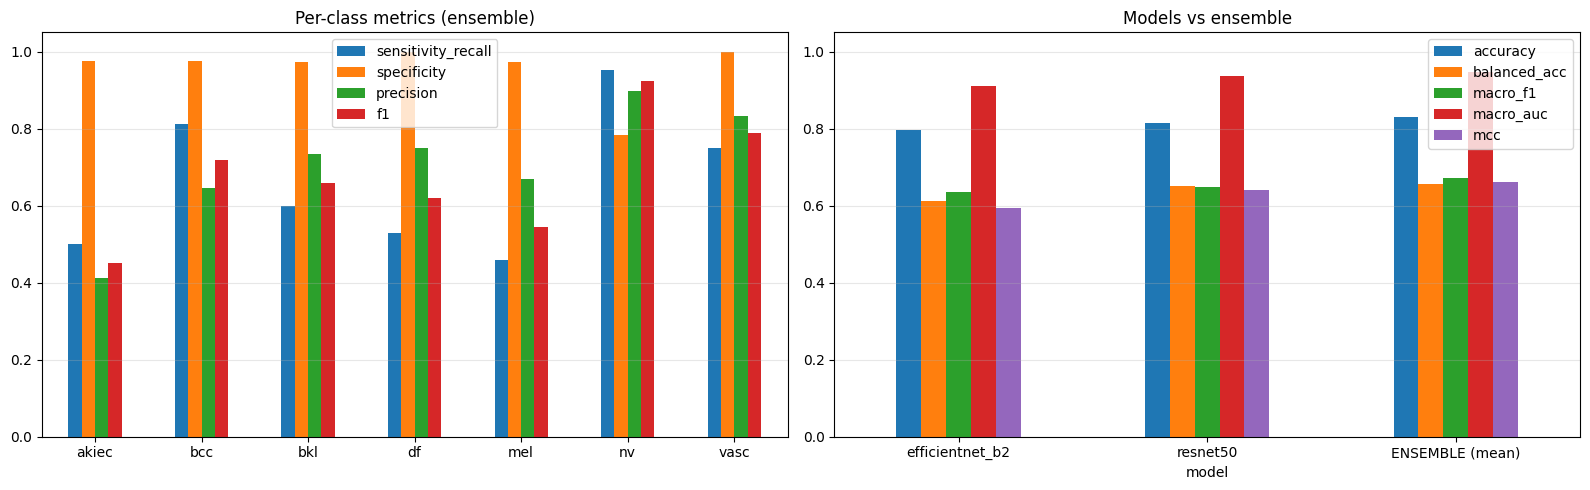

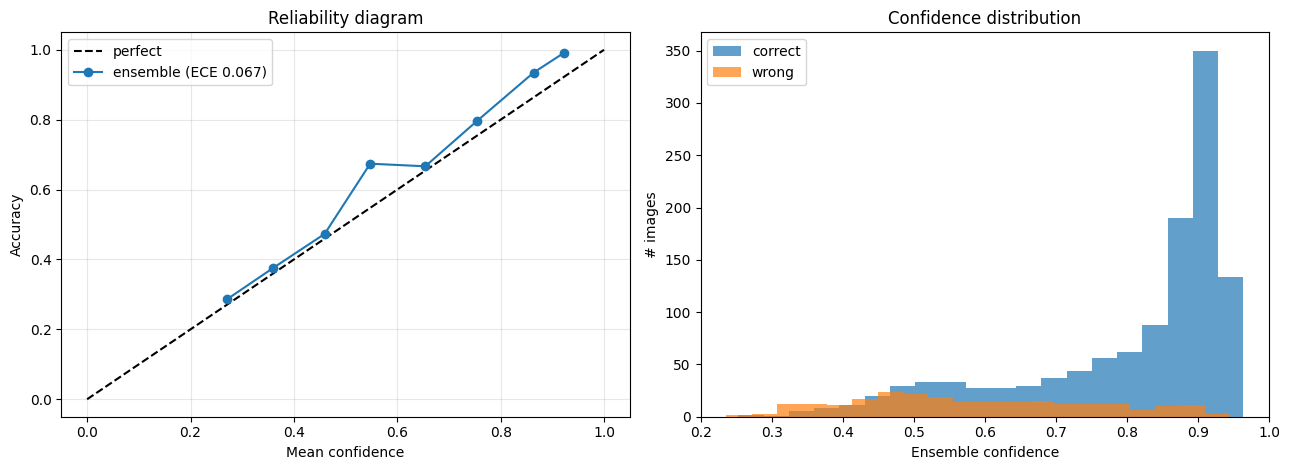

In [2]:
# ===================== CELL 2: TEST ON HAM10000 (held-out test split) =====================
# Only HAM10000 images that were never used for training or validation (lesion-disjoint test split).
ham_test = test_df[test_df["source"] == "HAM10000"].reset_index(drop=True)
print("HAM10000 test images:", len(ham_test)); print(ham_test["label"].value_counts().reindex(CLASSES).to_string())
PROBS["ham_test"] = get_probs(ham_test)
ham_summary, ham_per_class = full_report("HAM10000 held-out test", ham_test["y"].values, PROBS["ham_test"])

ISIC2019 test images: 2127
label
akiec    105
bcc      402
bkl      218
df        18
mel      487
nv       881
vasc      16

ISIC2019 held-out test  (n=2127)
          model  accuracy  top2_acc  balanced_acc  macro_precision  macro_recall  macro_f1  weighted_f1    mcc  kappa  macro_auc  macro_AP    ece  log_loss
efficientnet_b2    0.6939    0.8637        0.5327           0.5451        0.5327    0.5347       0.6904 0.5795 0.5788     0.8357    0.5449 0.0515    0.9878
       resnet50    0.6883    0.8778        0.5336           0.5269        0.5336    0.5281       0.6869 0.5708 0.5705     0.8944    0.5474 0.0382    0.8877
ENSEMBLE (mean)    0.7212    0.8928        0.5370           0.5836        0.5370    0.5540       0.7167 0.6148 0.6143     0.9060    0.6000 0.0302    0.8236

Ensemble 95% bootstrap CI:  accuracy [0.7038, 0.7393] | balanced_acc [0.4906, 0.5833] | macro_f1 [0.5034, 0.5991]
double-fault efficientnet_b2 & resnet50: 0.1984 | disagreement: 0.2694

Ensemble classification report:

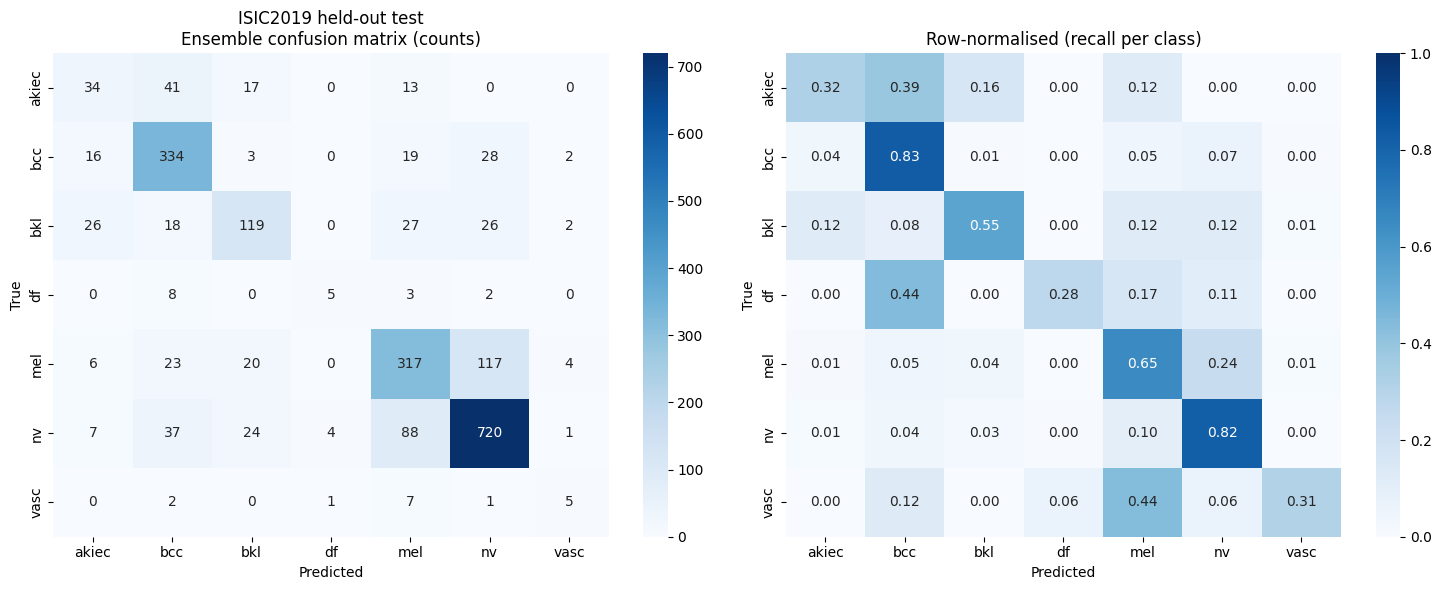

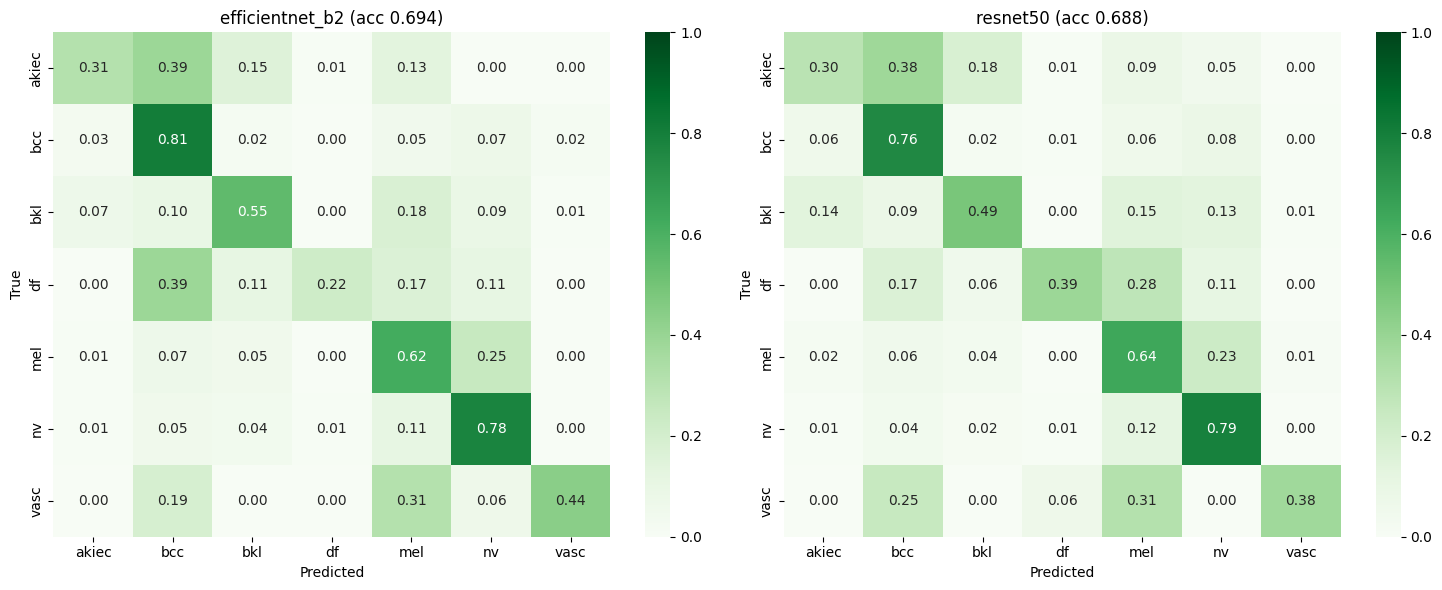

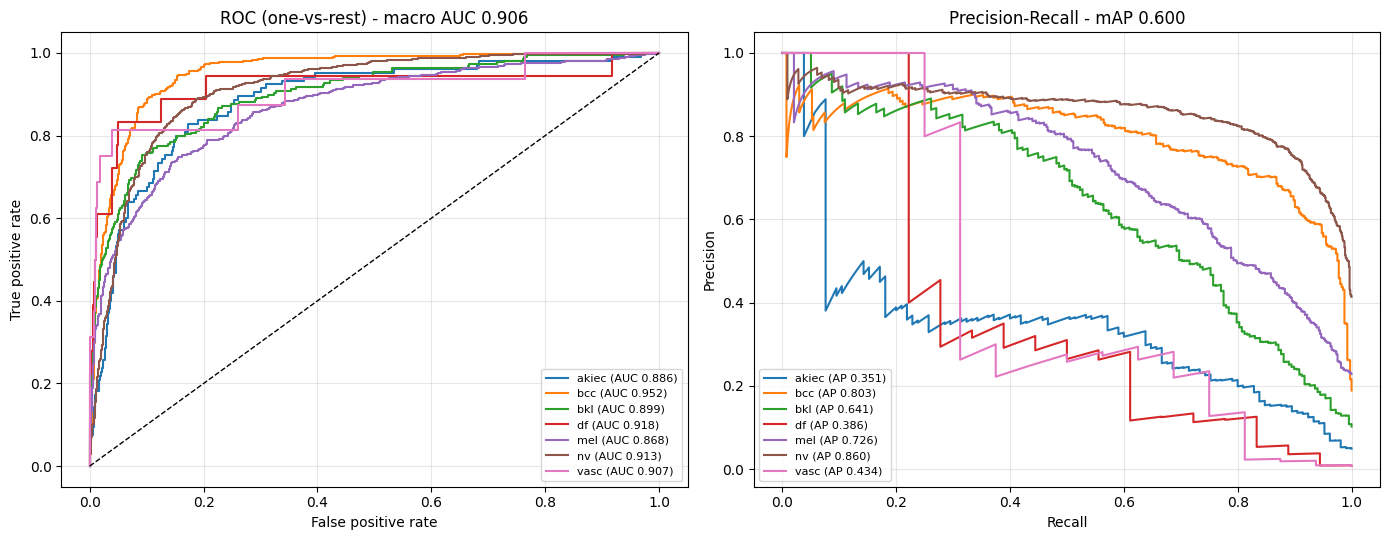

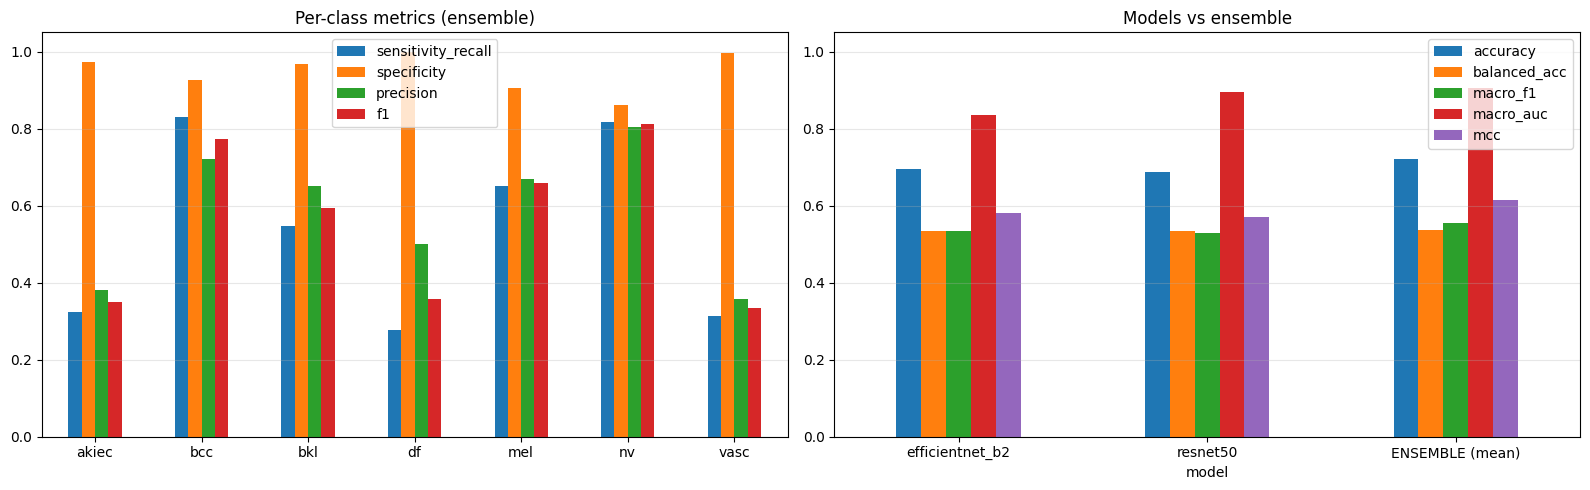

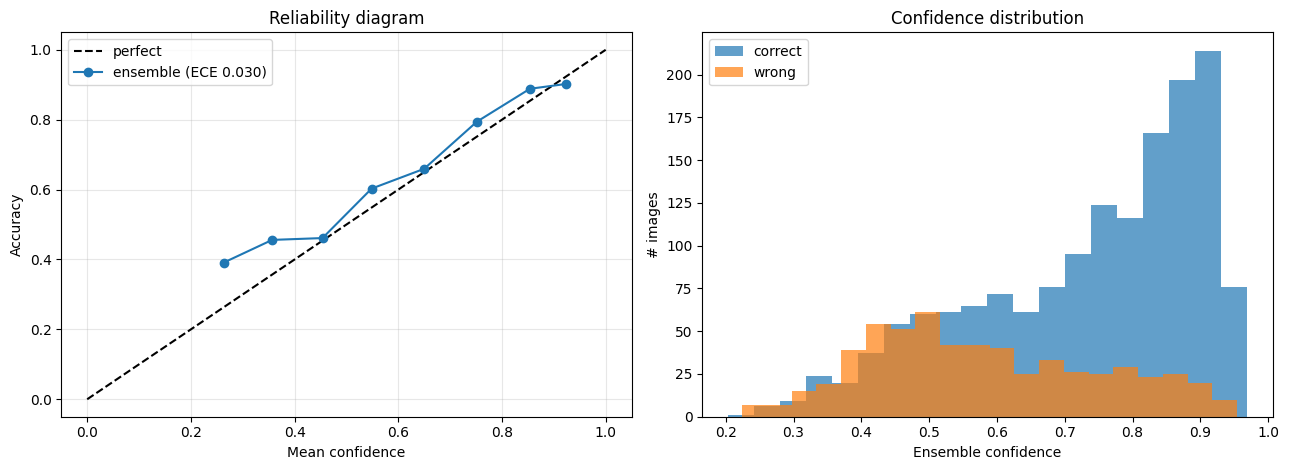


ENSEMBLE: HAM10000 test vs ISIC2019 test
                 HAM10000 test  ISIC2019 test
accuracy                0.8288         0.7212
top2_acc                0.9371         0.8928
balanced_acc            0.6572         0.5370
macro_precision         0.7060         0.5836
macro_recall            0.6572         0.5370
macro_f1                0.6727         0.5540
weighted_f1             0.8219         0.7167
mcc                     0.6619         0.6148
kappa                   0.6589         0.6143
macro_auc               0.9465         0.9060
macro_AP                0.7141         0.6000
ece                     0.0672         0.0302
log_loss                0.5470         0.8236


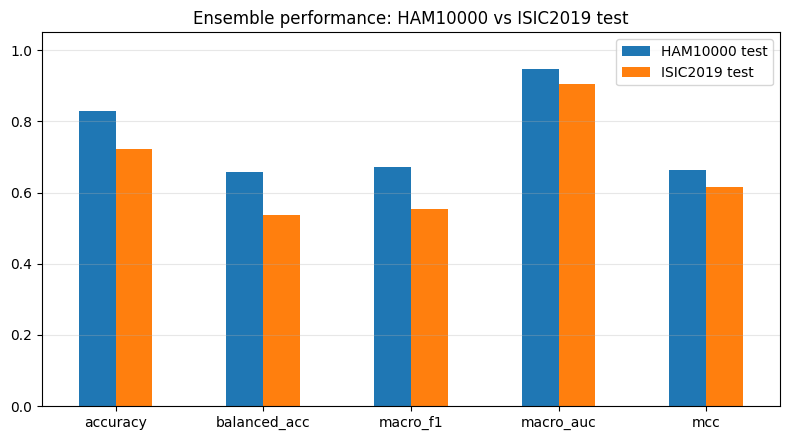

In [3]:
# ===================== CELL 3: TEST ON ISIC2019 (held-out test split) =====================
# Only ISIC2019 images that were never used for training or validation (HAM10000 duplicates already removed,
# lesion-disjoint where lesion_id is available).
isic_test = test_df[test_df["source"] == "ISIC2019"].reset_index(drop=True)
print("ISIC2019 test images:", len(isic_test)); print(isic_test["label"].value_counts().reindex(CLASSES).to_string())
PROBS["isic_test"] = get_probs(isic_test)
isic_summary, isic_per_class = full_report("ISIC2019 held-out test", isic_test["y"].values, PROBS["isic_test"])

# ---- side-by-side comparison of the two test sets (ensemble)
cmp_ = pd.concat({"HAM10000 test": ham_summary.set_index("model").loc["ENSEMBLE (mean)"],
                  "ISIC2019 test": isic_summary.set_index("model").loc["ENSEMBLE (mean)"]}, axis=1)
print("\n" + "=" * 70 + "\nENSEMBLE: HAM10000 test vs ISIC2019 test\n" + "=" * 70)
print(cmp_.round(4).to_string()); cmp_.to_csv(OUT_DIR / f"{TAG}_test_comparison.csv")
cmp_.loc[["accuracy", "balanced_acc", "macro_f1", "macro_auc", "mcc"]].plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.ylim(0, 1.05); plt.title("Ensemble performance: HAM10000 vs ISIC2019 test"); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / f"{TAG}_test_comparison.png", dpi=150); plt.show()